# Example distributions of tracked cyclones

This notebook shows how to load the output of the ERA5 DJF pipeline (`experiments/download_all/README.md`) and how to make distributions from it.

For every season and track resolution, `trackjson/seasons/<S><S+1>_DJF/` holds:

| File | Content |
|---|---|
| `…_<res>_vo_filtered.trackjson` | the filtered tracks (`postprocess_on_seasons.py`) |
| `…_<res>_vo_points_sl0p25.csv` | one row per track point, with the fields sampled along the track (`sample_on_seasons.py`) |
| `…_<res>_vo_summary_sl0p25.csv` | one row per track (lifetime and extremes of the columns above) |

`<res>` is the grid the tracking was done on (e.g. `0p25`, `3p0`). `sl0p25` means the single-level fields were sampled on the native 0.25° grid.

There are two kinds of distributions:

* **per point**: every 6-hourly position of every track. Long-lived storms contribute many points, so these distributions are weighted towards long tracks.
* **per track**: one value per storm, e.g. its maximum vorticity or its deepest central pressure. This is usually what is compared for intensity.

Genesis and lysis points are the least certain points of a track (the tracker picks up or loses a weak feature), so they are not plotted separately here.

## 1. Setup

The functions from `algorithms/` are imported the same way as in the other notebooks.

In [19]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import pystormtracker as pst

module_dir = (Path.cwd() / ".." / ".." / "algorithms").resolve()
sys.path.insert(0, str(module_dir))
import helpers
from configs import REGION, DOMAIN, SL_AREA, SAMPLE_CONFIG
from plotting import setup_plotting, geo_map, add_colorbar

colors = setup_plotting()
plt.rcParams["axes.formatter.limits"] = (-4, 5)   # plain numbers on the axes (e.g. 1000 hPa, not 1.0 x 1e3)

`TRACK_DIR` is the folder with the season folders. `SAMPLE_GRID` selects which sampled CSV files are read (`sl0p25` = fields on the native ERA5 grid).

In [20]:
TRACK_DIR = Path("/Volumes/ExtDisk/ERA5/trackjson")
SAMPLE_GRID = "sl0p25"

R_EARTH_KM = 6371.0
GALE, STORM = 17.2, 24.5   # m s-1, Beaufort 8 and 10


def res_from_tag(tag):
    # '0p25' -> 0.25, '1p875' -> 1.875
    return float(tag.replace("p", "."))


def res_label(res):
    return f"{res:g}°"


print(TRACK_DIR)
sorted(p.name for p in TRACK_DIR.glob("*_DJF"))

/Volumes/ExtDisk/ERA5/trackjson


['._20152016_DJF',
 '._20162017_DJF',
 '._20172018_DJF',
 '._20182019_DJF',
 '._20192020_DJF',
 '._20202021_DJF',
 '._20212022_DJF',
 '._20222023_DJF',
 '._20232024_DJF',
 '._20242025_DJF',
 '20152016_DJF',
 '20162017_DJF',
 '20172018_DJF',
 '20182019_DJF',
 '20192020_DJF',
 '20202021_DJF',
 '20212022_DJF',
 '20222023_DJF',
 '20232024_DJF',
 '20242025_DJF']

## 2. Loading

### 2.1 One file at a time

The filtered tracks are a pystormtracker `Tracks` object. `helpers.tracks_to_points` turns it into a table with one row per point and one column per track variable:
* `vo` (the T6–42 filtered vorticity, s⁻¹)
* `raw_value` (the same before the B-spline refinement)
* the `object_*` variables (currently all 0, the tracker does not compute them with the present settings)

In [21]:
season_dir = TRACK_DIR / "19981999_DJF"
tracks = pst.load_tracks(season_dir / "19981999_DJF_0p25_vo_filtered.trackjson")
print(f"{len(tracks)} tracks, {len(tracks.times)} points, variables: {list(tracks.variables)}")

track_points = helpers.tracks_to_points(tracks)
track_points.head()

ValueError: Unable to read TrackJSON file /Volumes/ExtDisk/ERA5/trackjson/19981999_DJF/19981999_DJF_0p25_vo_filtered.trackjson: [Errno 2] No such file or directory: '/Volumes/ExtDisk/ERA5/trackjson/19981999_DJF/19981999_DJF_0p25_vo_filtered.trackjson'

The points CSV contains the same rows plus the sampled fields and some per-point quantities derived from the track:

| Column | Unit | Meaning |
|---|---|---|
| `inside_area` | | False if the 500 km sampling circle is not inside `SL_AREA`; those points have NaN single-level values |
| `msl_min`, `msl_center` | hPa | minimum mean sea level pressure within 500 km, and the value at the track point |
| `ws10_max`, `ws10_mean` | m s⁻¹ | maximum and mean 10 m wind speed within 500 km |
| `vo850_unfilt_max` | s⁻¹ | maximum unfiltered 850 hPa vorticity within 500 km |
| `ws850_max` | m s⁻¹ | maximum 850 hPa wind speed within 500 km |
| `speed_kmh`, `direction_deg` | km h⁻¹, ° | motion since the previous point (0° = towards north, 90° = towards east) |
| `dvo_dt` | s⁻¹ per 6 h | change of `vo` |
| `dmsl_24h`, `deepening_bergeron` | hPa, Bergeron | 24 h change of `msl_min`, and the deepening normalised to 60°N (≥ 1 = explosive cyclone) |

The summary CSV has one row per track with `<column>_max` (or `_min` for pressure) over the track's lifetime.

In [ ]:
pd.read_csv(season_dir / f"19981999_DJF_0p25_vo_points_{SAMPLE_GRID}.csv", parse_dates=["time"]).head()

,track_id,time,lat,lon,vo,raw_value,object_gridcell_area_km2,object_moment_fitted_area_km2,object_moment_major_axis_km,object_moment_minor_axis_km,...,msl_center,ws10_max,ws10_mean,vo850_unfilt_max,ws850_max,speed_kmh,direction_deg,dvo_dt,dmsl_24h,deepening_bergeron
0,600,1998-12-01 00:00:00,60.75,-43.50,0.000044,0.000044,0.0,0.0,0.0,0.0,...,996.450000,17.360281,10.717174,0.000592,21.988268,NaN,NaN,NaN,NaN,NaN
1,600,1998-12-01 06:00:00,61.25,-41.75,0.000049,0.000049,0.0,0.0,0.0,0.0,...,996.546875,19.110651,10.804639,0.000577,25.482155,18.249741,58.724468,4.881265e-06,NaN,NaN
2,600,1998-12-01 12:00:00,62.50,-37.75,0.000050,0.000050,0.0,0.0,0.0,0.0,...,999.191875,19.346281,10.653195,0.000648,27.689548,41.914545,54.705800,1.710781e-06,NaN,NaN
3,600,1998-12-01 18:00:00,63.75,-34.25,0.000048,0.000048,0.0,0.0,0.0,0.0,...,1000.344375,21.503633,10.625942,0.000736,32.738533,37.359630,50.137205,-1.996246e-06,NaN,NaN
4,600,1998-12-02 00:00:00,64.75,-30.75,0.000049,0.000049,0.0,0.0,0.0,0.0,...,1002.315000,22.012737,10.395367,0.000732,33.089184,33.720467,55.101095,5.062357e-07,5.4675,-0.221921


### 2.2 All seasons and resolutions

`load_all` reads every CSV of the chosen sample grid and adds `season` and `res` columns. This gives two tidy tables that are easy to group and filter. It reads whatever is on disk, so the notebook keeps working when more seasons are added.

In [ ]:
def load_all(kind, sample_grid=SAMPLE_GRID, track_dir=TRACK_DIR):
    # kind = 'points' or 'summary'
    tables = []
    for season_dir in sorted(track_dir.glob("*_DJF")):
        for path in sorted(season_dir.glob(f"*_vo_{kind}_{sample_grid}.csv")):
            parts = path.name.split("_")              # 19981999 DJF 0p25 vo points sl0p25.csv
            df = pd.read_csv(path, parse_dates=["time"] if kind == "points" else ["start_time", "end_time"])
            df.insert(0, "season", season_dir.name)
            df.insert(1, "res", res_from_tag(parts[2]))
            tables.append(df)
    return pd.concat(tables, ignore_index=True) if tables else pd.DataFrame()


points = load_all("points")
summary = load_all("summary")

# vorticity in the usual units of 1e-5 s-1
points["vo_1e5"] = points["vo"] * 1e5
summary["vo_max_1e5"] = summary["vo_max"] * 1e5

RESOLUTIONS = sorted(float(r) for r in points["res"].unique())
SEASONS = sorted(points["season"].unique())
RES_COLOR = {r: colors[i % len(colors)] for i, r in enumerate(RESOLUTIONS)}
print("seasons:", SEASONS)
print("resolutions:", RESOLUTIONS)

seasons: ['19981999_DJF', '19992000_DJF']
resolutions: [0.25, 1.0, 1.25, 1.875, 3.0]


### 2.3 Sanity checks

* Number of tracks and points per season and resolution.
* The CSV must contain exactly the points of the filtered tracks.
* How many points lie outside the single-level area (NaN for the single-level fields).

In [ ]:
counts = points.groupby(["season", "res"]).agg(tracks=("track_id", "nunique"), points=("track_id", "size"),
                                                outside_area=("inside_area", lambda s: int((~s).sum())))

def n_track_points(season, res):
    tag = f"{res:g}" if "." in f"{res:g}" else f"{res:g}.0"
    path = TRACK_DIR / season / f"{season}_{tag.replace('.', 'p')}_vo_filtered.trackjson"
    return len(pst.load_tracks(path).times)

counts["points_in_trackjson"] = [n_track_points(s, r) for s, r in counts.index]
assert (counts["points"] == counts["points_in_trackjson"]).all(), "CSV and trackjson differ"
counts

tracks  points  outside_area  points_in_trackjson
season       res                                                     
19981999_DJF 0.250     124    1971            18                 1971
             1.000     116    1839            17                 1839
             1.250     124    1869            16                 1869
             1.875     115    1701            15                 1701
             3.000      71     836             4                  836
19992000_DJF 0.250     126    2073            32                 2073
             1.000     127    2112            33                 2112
             1.250     133    2089            34                 2089
             1.875     122    1847            21                 1847
             3.000      77     840             0                  840

## 3. Distributions from the filtered tracks

These use only what the tracker produced: positions and the filtered vorticity.

### 3.1 Track density

The number of track points per 2.5° × 2.5° box, divided by the box area and the number of seasons. That gives points per season per 10⁵ km², so boxes at high latitudes (which are smaller) are not under-counted.

The map stops at 85°N: the boxes closest to the pole are so small that a handful of points gives a misleading density there.

The left map is the 0.25° tracking. The right map is the difference between the coarsest and the native resolution: red means more track points on the coarse grid.

/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.1

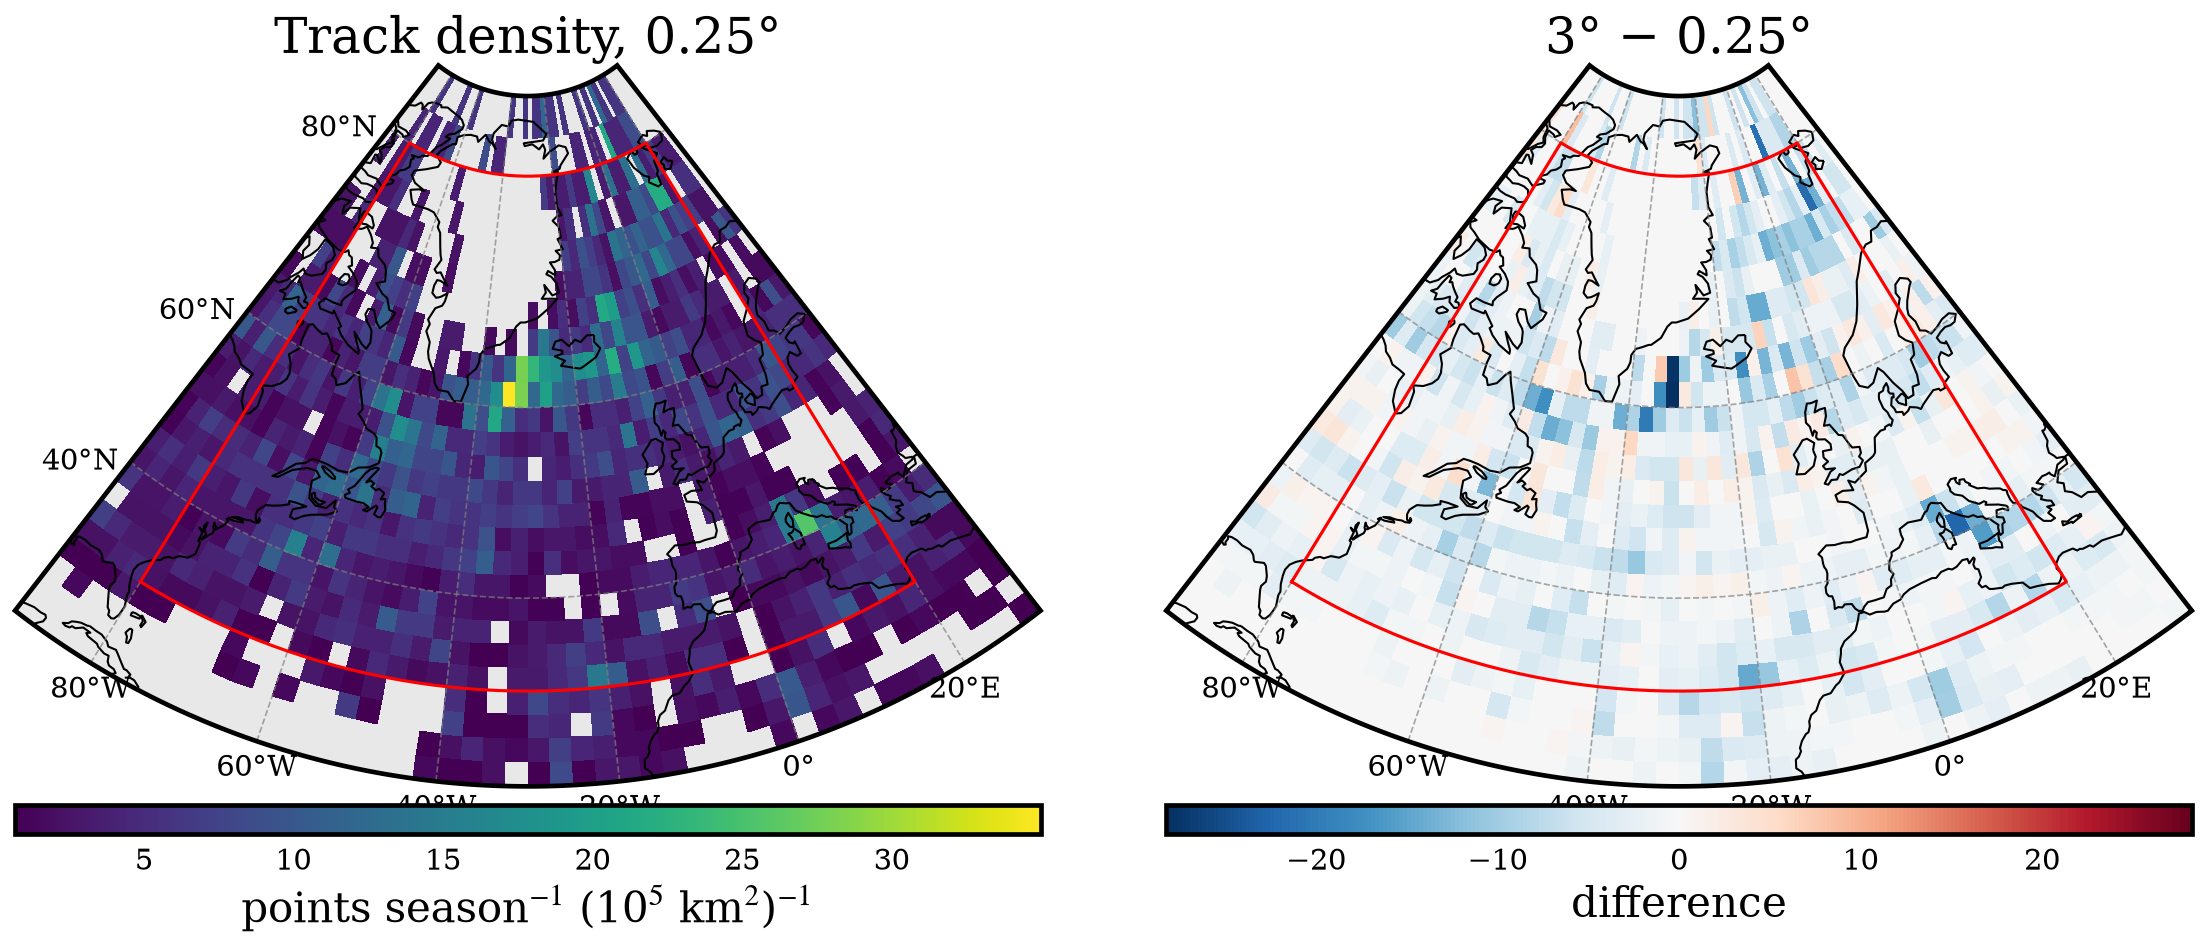

In [ ]:
MAP_EXTENT = [DOMAIN[0], DOMAIN[1], DOMAIN[2], 85]


def density_map(df, n_seasons, dx=2.5, extent=MAP_EXTENT):
    lon_edges = np.arange(extent[0], extent[1] + dx, dx)
    lat_edges = np.arange(extent[2], extent[3] + dx, dx)
    counts, _, _ = np.histogram2d(df["lon"], df["lat"], bins=[lon_edges, lat_edges])
    # area of each box in km2
    area = (R_EARTH_KM**2 * np.radians(dx)
            * (np.sin(np.radians(lat_edges[1:])) - np.sin(np.radians(lat_edges[:-1]))))
    density = counts / area[None, :] * 1e5 / n_seasons
    return lon_edges, lat_edges, density.T


def draw_box(ax, box, **kw):
    lo = np.linspace(box[0], box[1], 100)
    la = np.linspace(box[2], box[3], 100)
    xs = np.concatenate([lo, np.full(100, box[1]), lo[::-1], np.full(100, box[0])])
    ys = np.concatenate([np.full(100, box[2]), la, np.full(100, box[3]), la[::-1]])
    ax.plot(xs, ys, transform=ccrs.PlateCarree(), lw=1.5, **kw)


fine, coarse = RESOLUTIONS[0], RESOLUTIONS[-1]
maps = {r: density_map(points[points.res == r], points.loc[points.res == r, "season"].nunique())
        for r in (fine, coarse)}

proj = ccrs.LambertConformal(central_longitude=-30, central_latitude=55)
fig, axes = geo_map(proj, extent=MAP_EXTENT, ncols=2, width=16)

lon_e, lat_e, d_fine = maps[fine]
im = axes[0].pcolormesh(lon_e, lat_e, np.where(d_fine > 0, d_fine, np.nan), cmap="viridis",
                        transform=ccrs.PlateCarree())
add_colorbar(im, axes[0], label="points season$^{-1}$ (10$^5$ km$^2$)$^{-1}$", location="bottom")
axes[0].set_title(f"Track density, {res_label(fine)}")

diff = maps[coarse][2] - d_fine
lim = np.nanmax(np.abs(diff))
im = axes[1].pcolormesh(lon_e, lat_e, diff, cmap="RdBu_r", vmin=-lim, vmax=lim, transform=ccrs.PlateCarree())
add_colorbar(im, axes[1], label="difference", location="bottom")
axes[1].set_title(f"{res_label(coarse)} − {res_label(fine)}")

for ax in axes:
    draw_box(ax, DOMAIN, color="k", ls="--")
    draw_box(ax, REGION, color="red")
plt.show()

### 3.2 Latitude and longitude of the track points

Normalised histograms (density), one line per tracking resolution. A shift between the lines shows that the coarse grids place storms differently, e.g. lose the small systems at low latitudes or merge systems in the storm-track exit region.

The track positions lie on the grid points of the tracking grid (e.g. multiples of 3° on the 3° grid). Narrow bins would therefore give spiky, aliased histograms for the coarse grids, so the bins here are 5° in latitude and 10° in longitude.

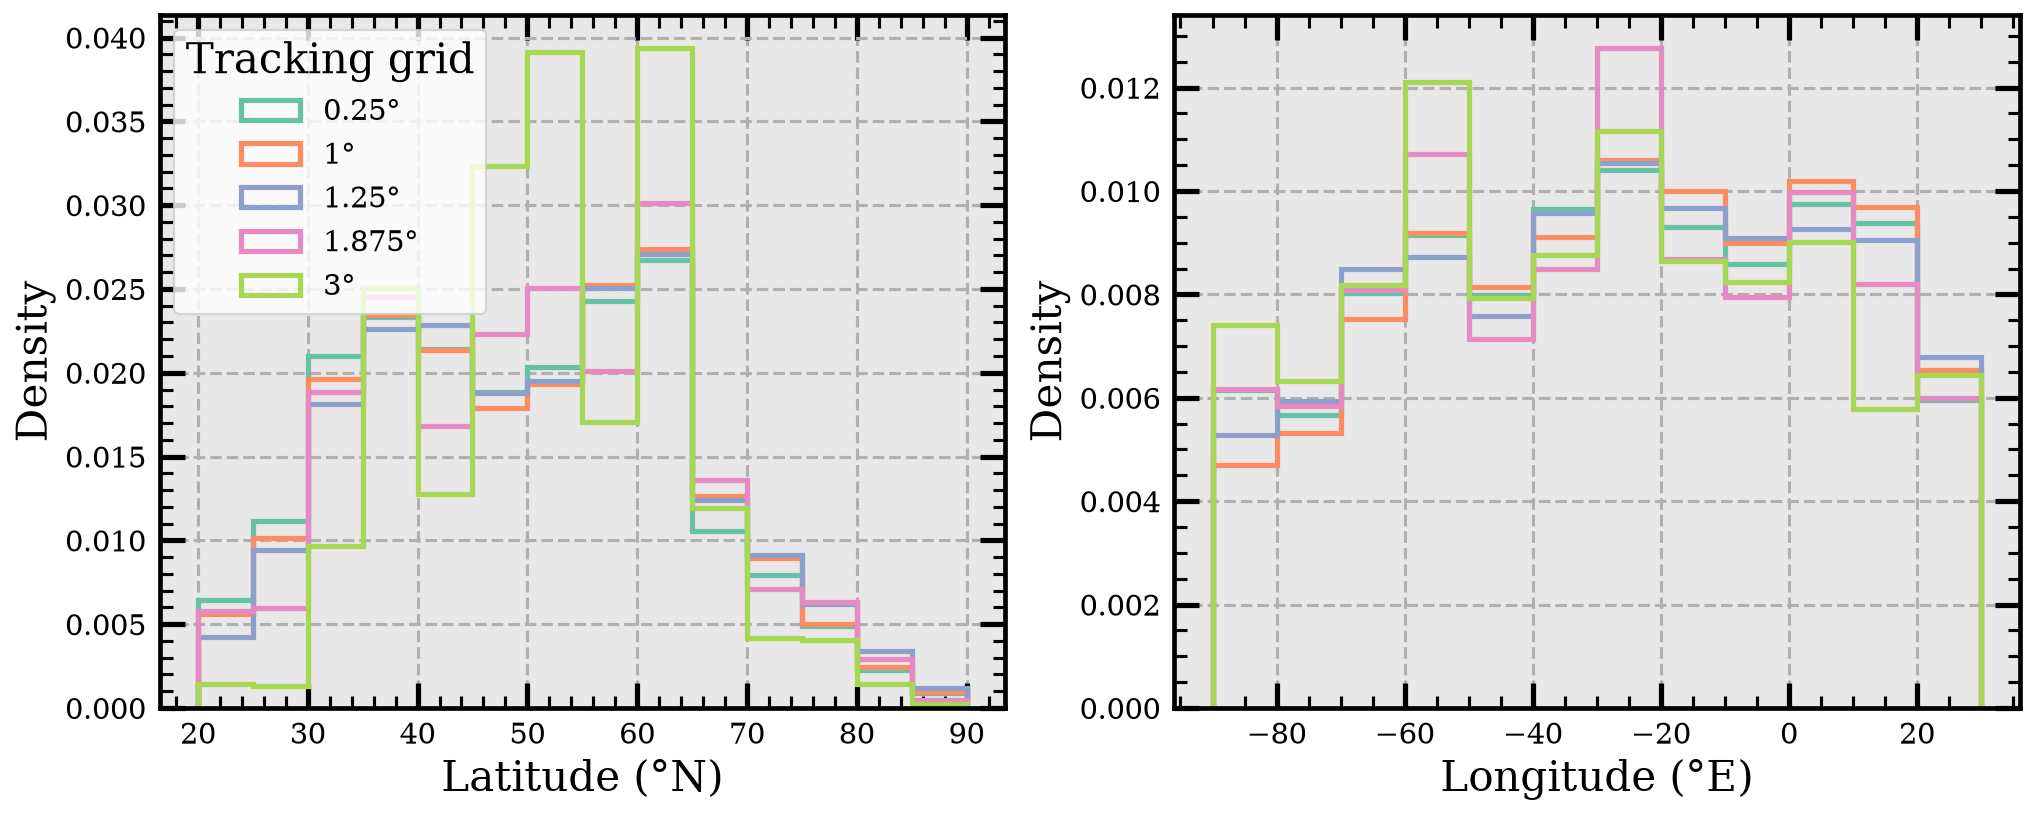

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for r in RESOLUTIONS:
    sel = points[points.res == r]
    ax1.hist(sel["lat"], bins=np.arange(20, 91, 5), density=True, histtype="step", lw=2.5,
             color=RES_COLOR[r], label=res_label(r))
    ax2.hist(sel["lon"], bins=np.arange(-90, 31, 10), density=True, histtype="step", lw=2.5,
             color=RES_COLOR[r], label=res_label(r))
ax1.set(xlabel="Latitude (°N)", ylabel="Density")
ax2.set(xlabel="Longitude (°E)", ylabel="Density")
ax1.legend(title="Tracking grid")
plt.show()

### 3.3 Vorticity

Left: the filtered vorticity of **all points** (weighted towards long tracks and including the weak start and end of every track). Right: the **maximum per track**, the usual measure of storm intensity. The tracker threshold is 1 × 10⁻⁵ s⁻¹, so nothing lies below it.

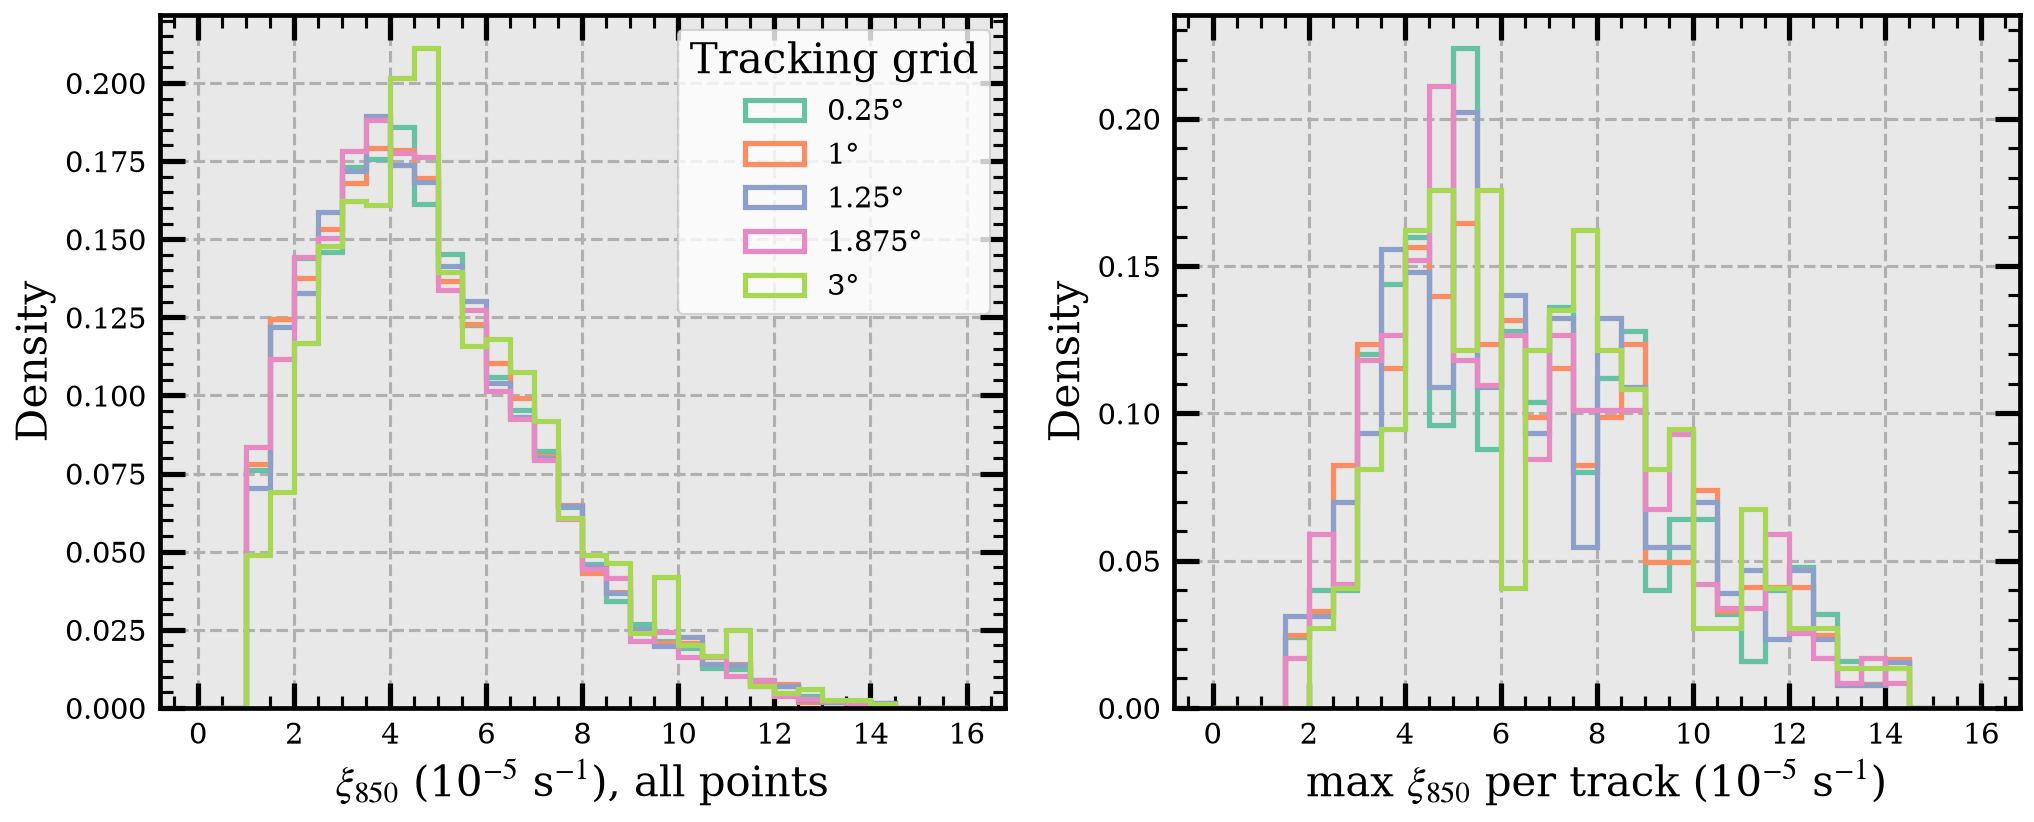

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
bins = np.arange(0, 16.5, 0.5)
for r in RESOLUTIONS:
    ax1.hist(points.loc[points.res == r, "vo_1e5"], bins=bins, density=True, histtype="step", lw=2.5,
             color=RES_COLOR[r], label=res_label(r))
    ax2.hist(summary.loc[summary.res == r, "vo_max_1e5"], bins=bins, density=True, histtype="step", lw=2.5,
             color=RES_COLOR[r], label=res_label(r))
ax1.set(xlabel=r"$\xi_{850}$ (10$^{-5}$ s$^{-1}$), all points", ylabel="Density")
ax2.set(xlabel=r"max $\xi_{850}$ per track (10$^{-5}$ s$^{-1}$)", ylabel="Density")
ax1.legend(title="Tracking grid")
plt.show()

### 3.4 Lifetime and number of tracks

Left: the lifetime of the filtered tracks (the post-processing keeps tracks of at least 8 points, i.e. 42 h). Right: the number of tracks per season and resolution.

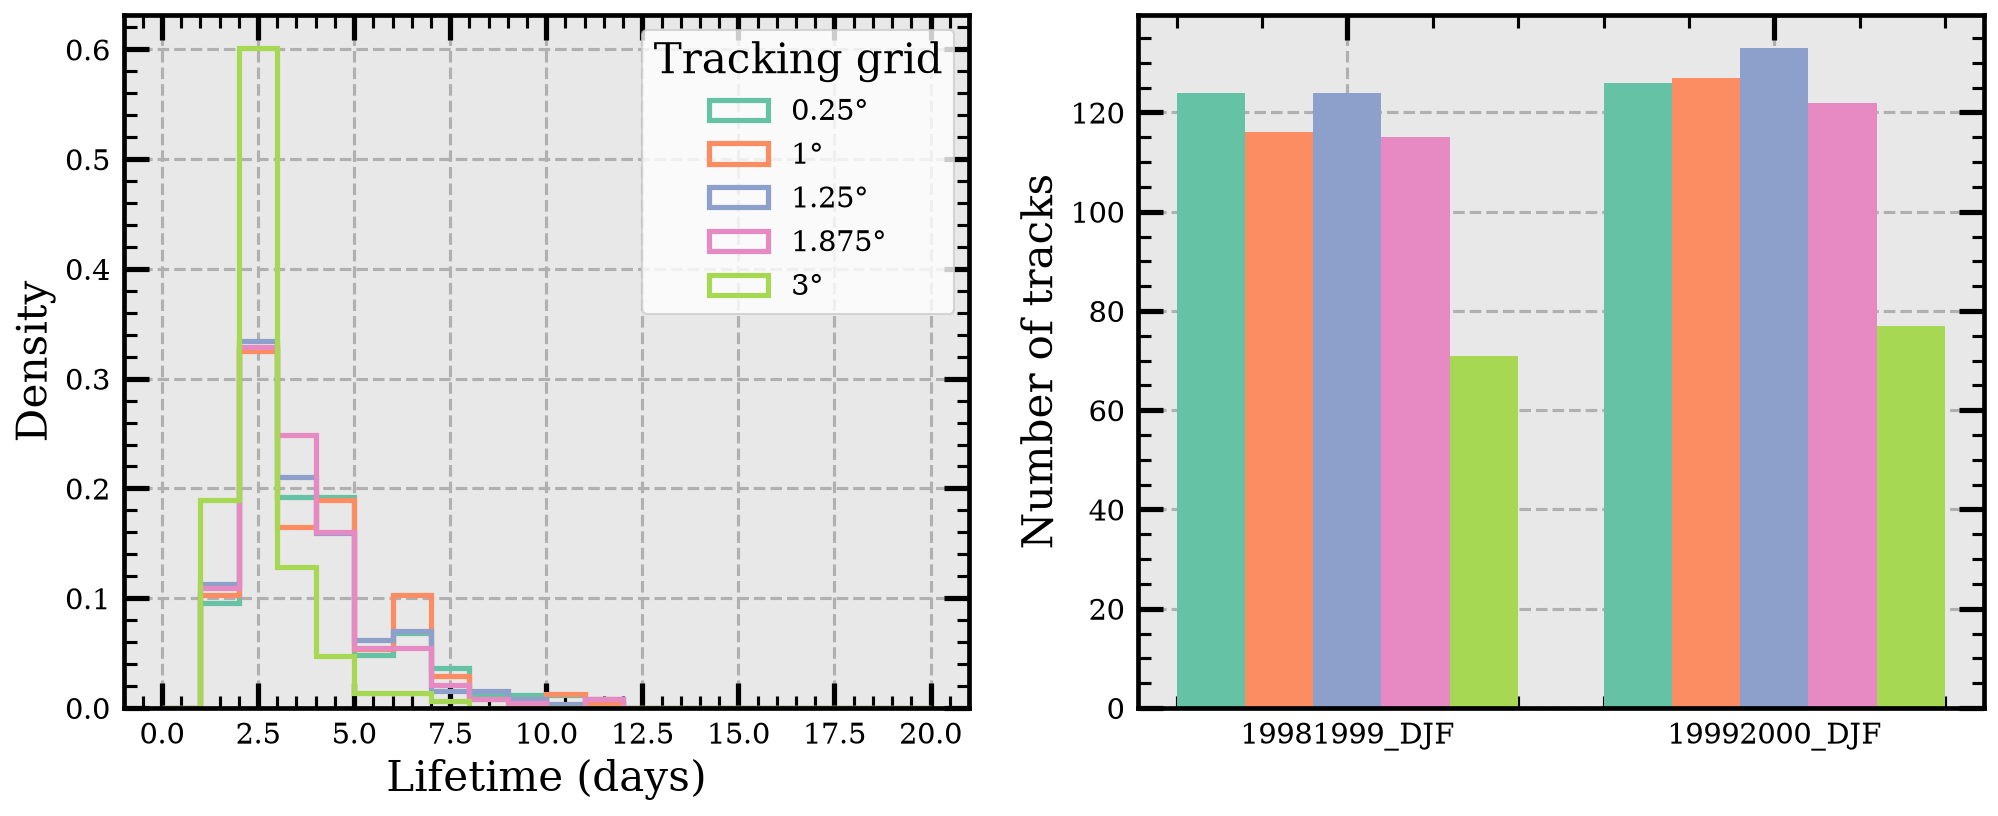

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for r in RESOLUTIONS:
    ax1.hist(summary.loc[summary.res == r, "duration_h"] / 24, bins=np.arange(0, 21, 1), density=True,
             histtype="step", lw=2.5, color=RES_COLOR[r], label=res_label(r))
ax1.set(xlabel="Lifetime (days)", ylabel="Density")
ax1.legend(title="Tracking grid")

n_tracks = summary.groupby(["season", "res"]).size().unstack("res")
width = 0.8 / len(RESOLUTIONS)
x = np.arange(len(n_tracks))
for i, r in enumerate(RESOLUTIONS):
    ax2.bar(x + i * width, n_tracks[r], width=width, color=RES_COLOR[r], label=res_label(r))
ax2.set_xticks(x + 0.4 - width / 2, n_tracks.index)
ax2.set(ylabel="Number of tracks")
plt.show()

### 3.5 Intensity against latitude

A 2D histogram of all points of the native-resolution tracks. It shows where along the storm track the systems are strongest. The filtered vorticity is not normalised by the Coriolis parameter, so it tends to be larger at high latitudes for the same circulation.

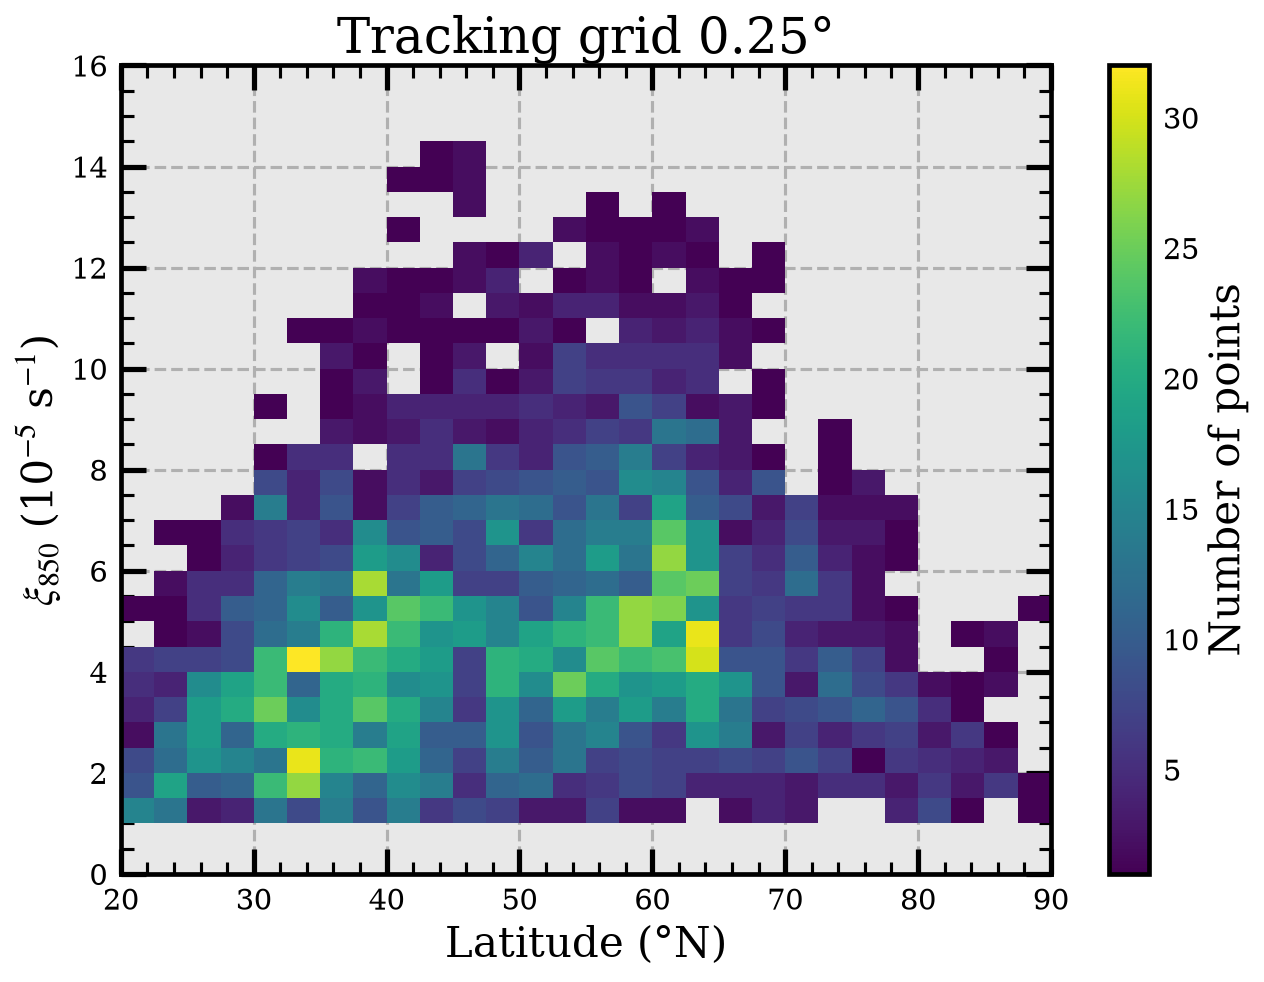

In [ ]:
sel = points[points.res == fine]
fig, ax = plt.subplots(figsize=(10, 7))
h = ax.hist2d(sel["lat"], sel["vo_1e5"], bins=[np.arange(20, 91, 2.5), np.arange(0, 16.5, 0.5)], cmin=1, cmap="viridis")
plt.colorbar(h[3], ax=ax, label="Number of points")
ax.set(xlabel="Latitude (°N)", ylabel=r"$\xi_{850}$ (10$^{-5}$ s$^{-1}$)", title=f"Tracking grid {res_label(fine)}")
plt.show()

## 4. Distributions from the sampled variables

These are the ERA5 fields sampled within 500 km of every track point (`SAMPLE_CONFIG` in `configs.py`). Points whose sampling circle is not inside the single-level area are NaN and are dropped with `.dropna()`.

### 4.1 Central pressure

Left: the deepest pressure each storm reaches (`msl_min_min` from the summary). Right: for the native-resolution tracks, the per-point `msl_min` (every time step) compared with the per-track minimum. This shows how strongly the per-point histogram is dominated by the weaker stages of the storms.

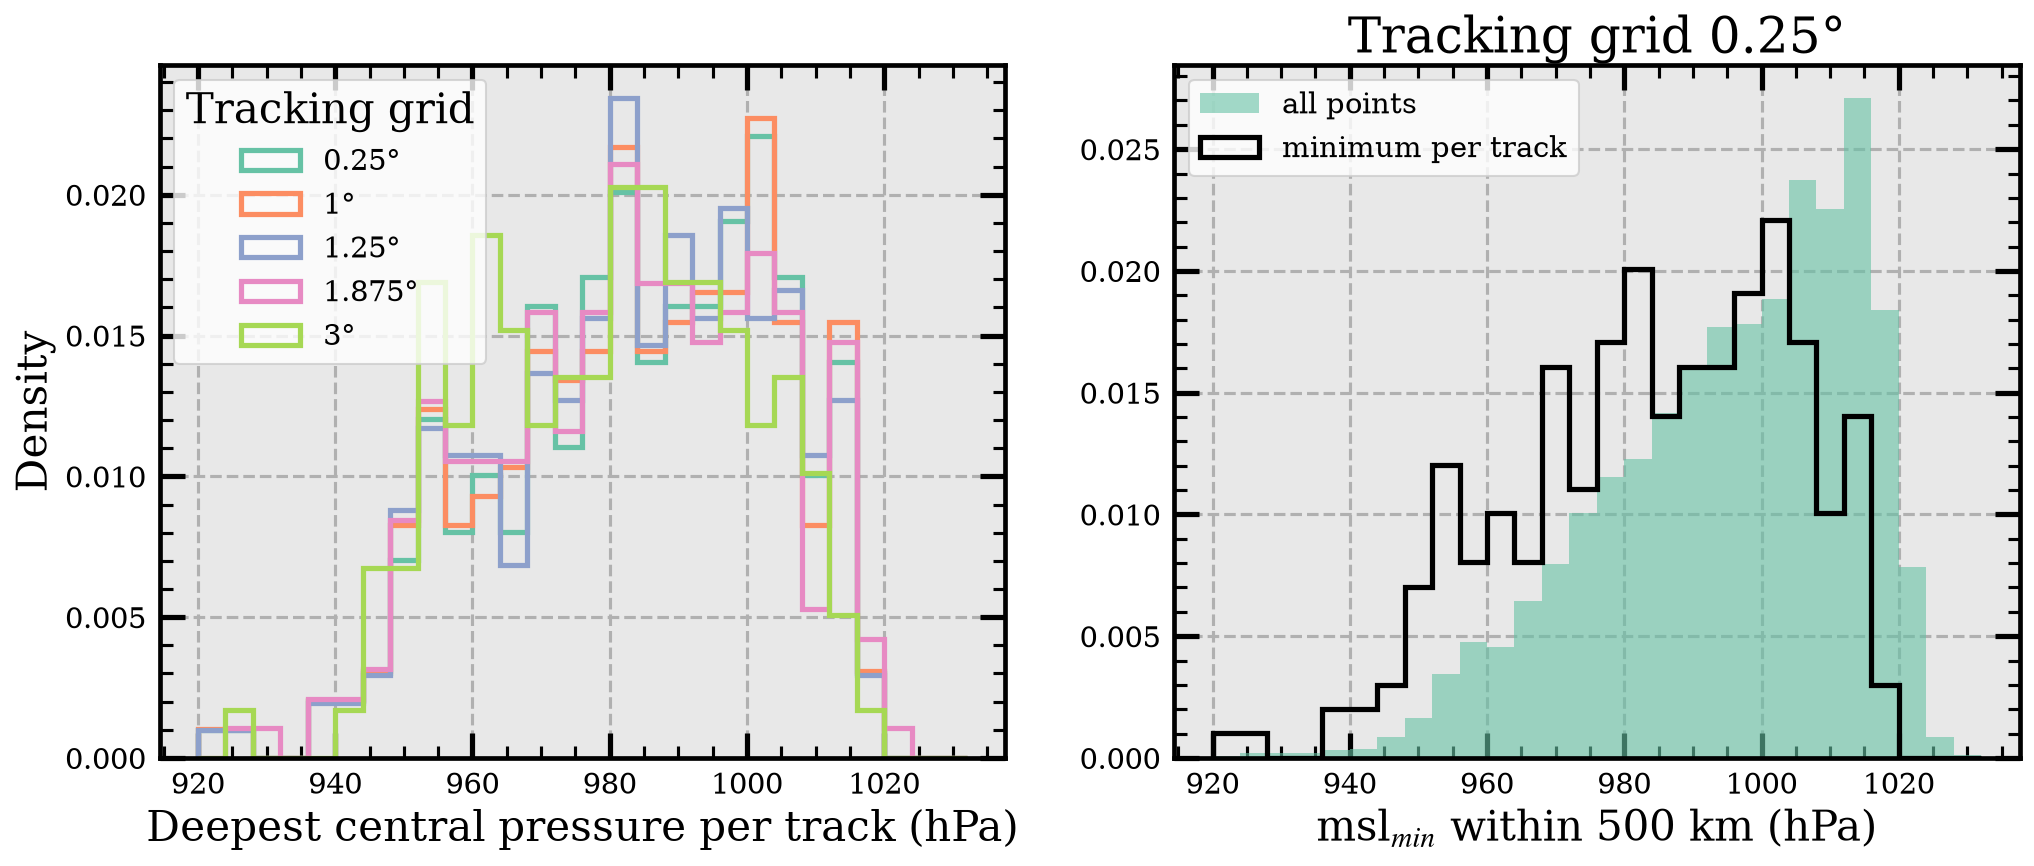

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
bins = np.arange(920, 1036, 4)
for r in RESOLUTIONS:
    ax1.hist(summary.loc[summary.res == r, "msl_min_min"].dropna(), bins=bins, density=True,
             histtype="step", lw=2.5, color=RES_COLOR[r], label=res_label(r))
ax1.set(xlabel="Deepest central pressure per track (hPa)", ylabel="Density")
ax1.legend(title="Tracking grid")

ax2.hist(points.loc[points.res == fine, "msl_min"].dropna(), bins=bins, density=True, alpha=0.6, label="all points")
ax2.hist(summary.loc[summary.res == fine, "msl_min_min"].dropna(), bins=bins, density=True, histtype="step",
         lw=2.5, color="k", label="minimum per track")
ax2.set(xlabel="msl$_{min}$ within 500 km (hPa)", title=f"Tracking grid {res_label(fine)}")
ax2.legend()
plt.show()

### 4.2 Wind

Left: the strongest 10 m wind within 500 km that each storm produces, with the gale (17.2 m s⁻¹) and storm (24.5 m s⁻¹) thresholds. Right: for the native-resolution tracks, the 10 m wind compared with the 850 hPa wind. The 850 hPa level is above most of the surface friction, so its winds are stronger.

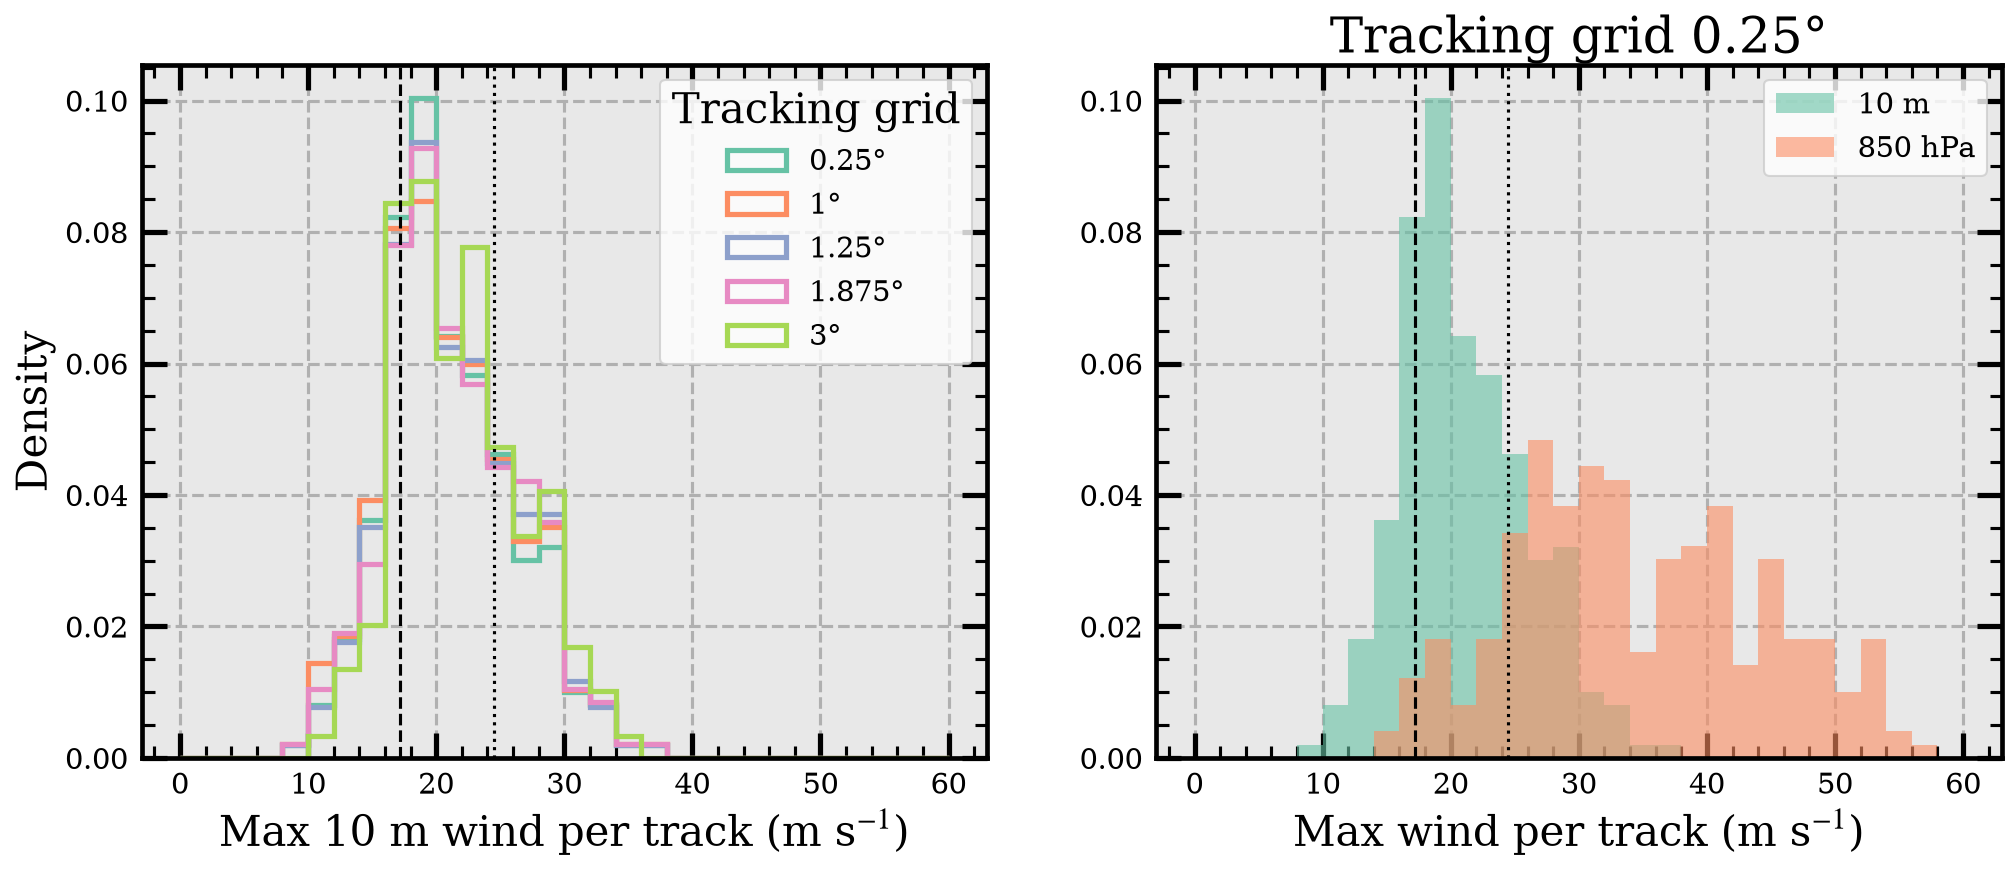

,fraction ≥ gale,fraction ≥ storm
res,,
0.250,0.78,0.23
1.000,0.76,0.24
1.250,0.78,0.25
1.875,0.78,0.25
3.000,0.82,0.27


In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
bins = np.arange(0, 61, 2)
for r in RESOLUTIONS:
    ax1.hist(summary.loc[summary.res == r, "ws10_max_max"].dropna(), bins=bins, density=True,
             histtype="step", lw=2.5, color=RES_COLOR[r], label=res_label(r))
for ax in (ax1, ax2):
    ax.axvline(GALE, color="k", ls="--", lw=1.5)
    ax.axvline(STORM, color="k", ls=":", lw=1.5)
ax1.set(xlabel="Max 10 m wind per track (m s$^{-1}$)", ylabel="Density")
ax1.legend(title="Tracking grid")

sel = summary[summary.res == fine]
ax2.hist(sel["ws10_max_max"].dropna(), bins=bins, density=True, alpha=0.6, label="10 m")
ax2.hist(sel["ws850_max_max"].dropna(), bins=bins, density=True, alpha=0.6, label="850 hPa")
ax2.set(xlabel="Max wind per track (m s$^{-1}$)", title=f"Tracking grid {res_label(fine)}")
ax2.legend()
plt.show()

frac_gale = summary.groupby("res")["ws10_max_max"].apply(lambda s: (s.dropna() >= GALE).mean())
frac_storm = summary.groupby("res")["ws10_max_max"].apply(lambda s: (s.dropna() >= STORM).mean())
pd.DataFrame({"fraction ≥ gale": frac_gale, "fraction ≥ storm": frac_storm}).round(2)

### 4.3 Explosive deepening

`deepening_bergeron` is the 24 h drop of the central pressure, normalised to 60°N (Sanders & Gyakum 1980). A storm with a maximum of at least 1 Bergeron somewhere in its life is an explosive cyclone ("bomb"). Coarse grids smooth the pressure minimum and shift the track, which can lower the deepening rates.

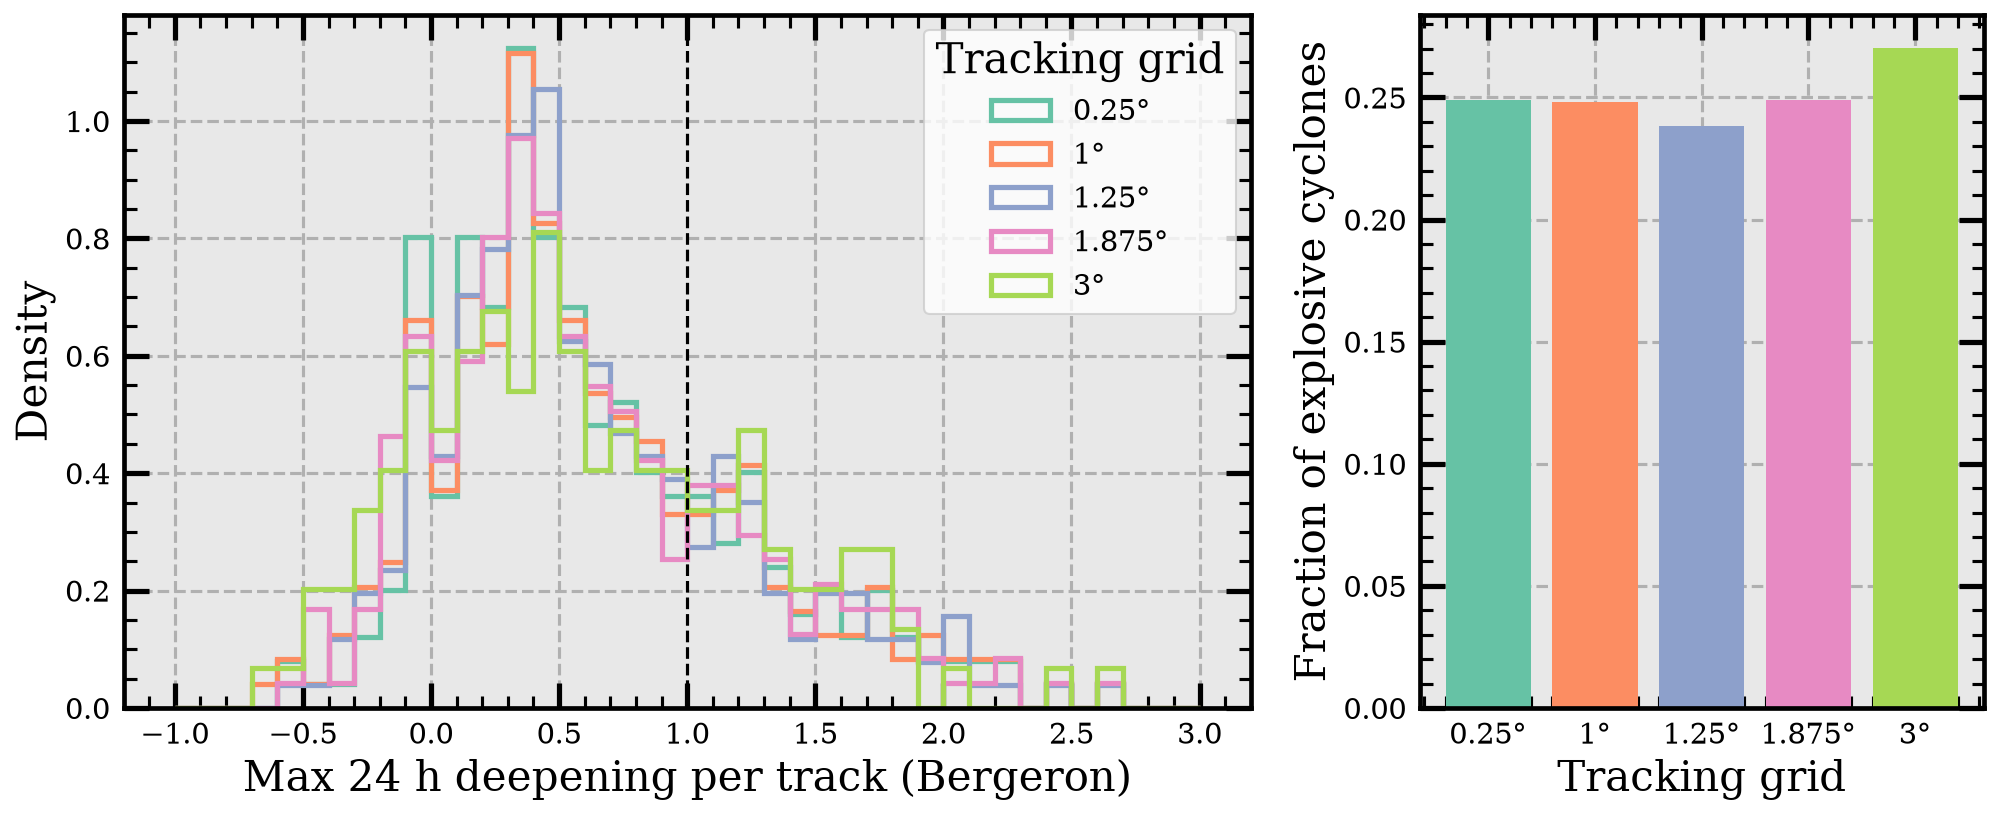

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2, 1]})
bins = np.arange(-1, 3.01, 0.1)
for r in RESOLUTIONS:
    ax1.hist(summary.loc[summary.res == r, "deepening_bergeron_max"].dropna(), bins=bins, density=True,
             histtype="step", lw=2.5, color=RES_COLOR[r], label=res_label(r))
ax1.axvline(1, color="k", ls="--", lw=1.5)
ax1.set(xlabel="Max 24 h deepening per track (Bergeron)", ylabel="Density")
ax1.legend(title="Tracking grid")

explosive = summary.groupby("res")["deepening_bergeron_max"].apply(lambda s: (s.dropna() >= 1).mean())
ax2.bar([res_label(r) for r in explosive.index], explosive.values, color=[RES_COLOR[r] for r in explosive.index])
ax2.set(ylabel="Fraction of explosive cyclones", xlabel="Tracking grid")
plt.show()

### 4.4 Motion

Left: the propagation speed between consecutive points. Right: a rose of the direction of motion for the native-resolution tracks. North Atlantic winter storms mostly move east to north-east. Large speeds at single points usually mean the tracker jumped between features.

Because the positions lie on the grid points, the distance between two points (and so the speed) can only take certain values on a coarse grid; 10 km h⁻¹ bins smooth this out.

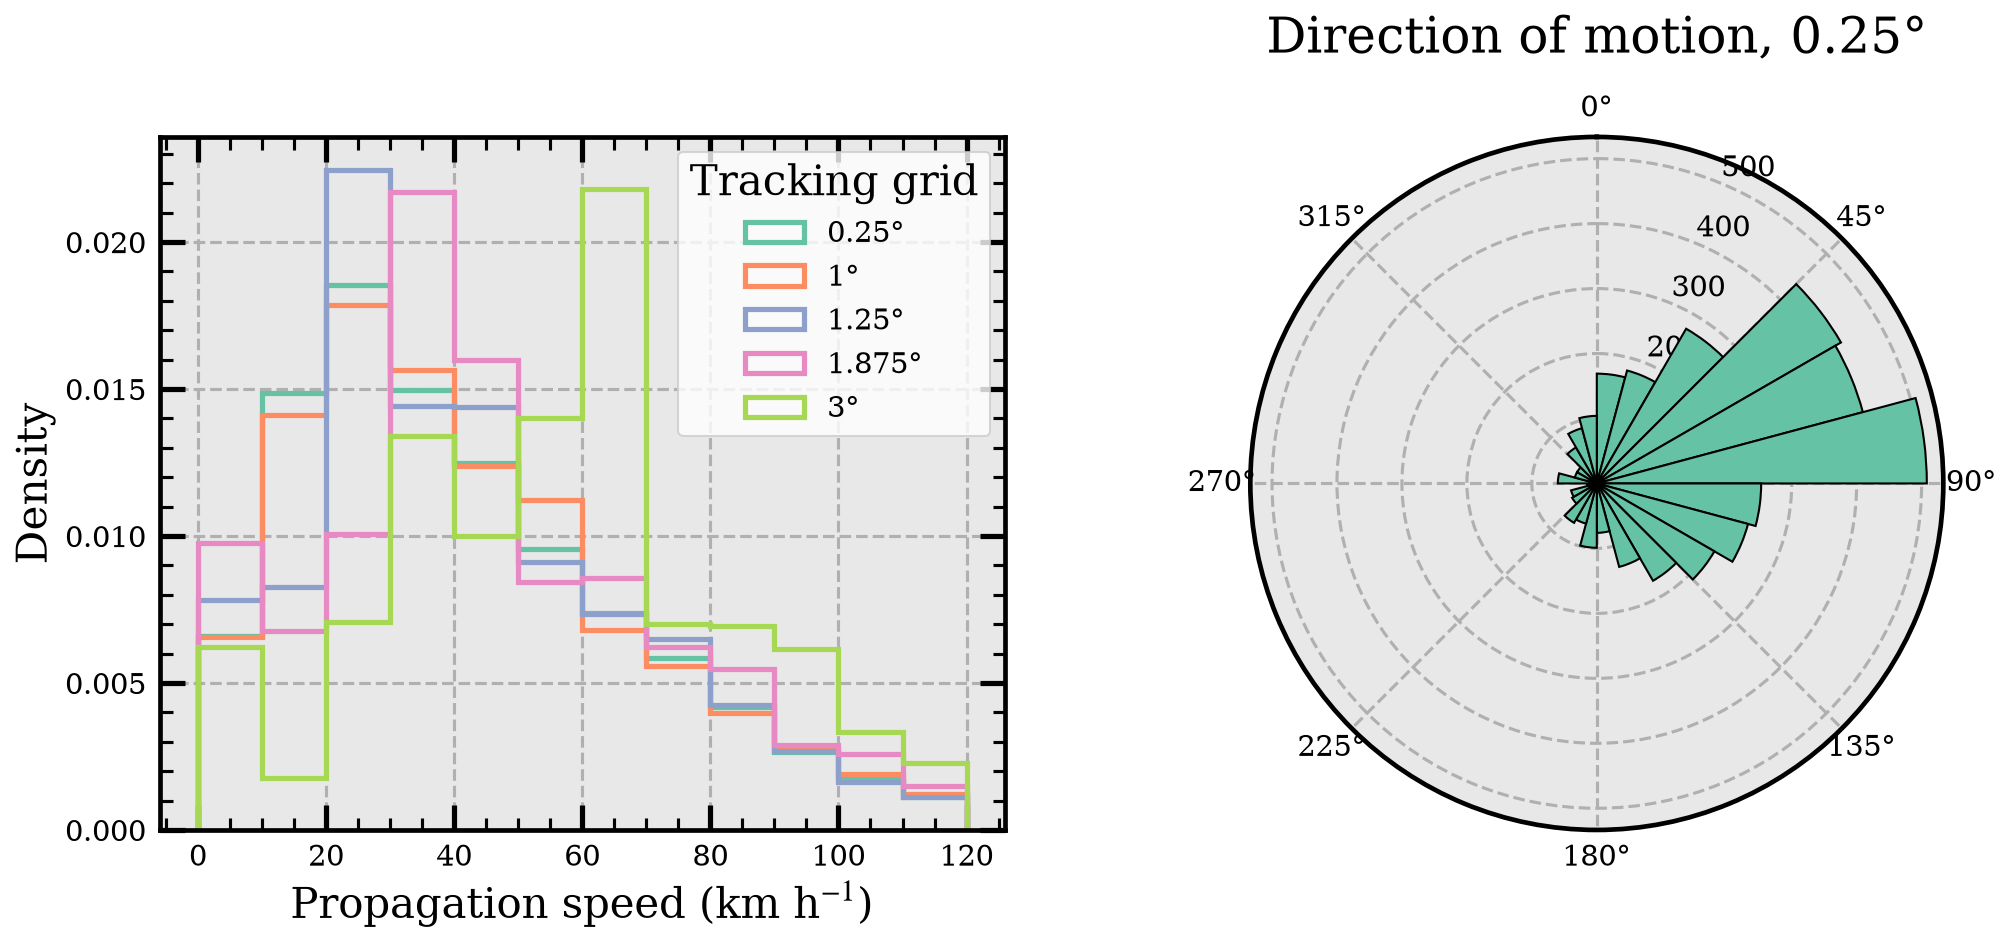

In [ ]:
fig = plt.figure(figsize=(16, 6))
ax1 = fig.add_subplot(1, 2, 1)
for r in RESOLUTIONS:
    ax1.hist(points.loc[points.res == r, "speed_kmh"].dropna(), bins=np.arange(0, 130, 10), density=True,
             histtype="step", lw=2.5, color=RES_COLOR[r], label=res_label(r))
ax1.set(xlabel="Propagation speed (km h$^{-1}$)", ylabel="Density")
ax1.legend(title="Tracking grid")

ax2 = fig.add_subplot(1, 2, 2, projection="polar")
direction = points.loc[points.res == fine, "direction_deg"].dropna()
counts_dir, edges = np.histogram(np.radians(direction), bins=np.linspace(0, 2 * np.pi, 25))
ax2.bar(edges[:-1], counts_dir, width=np.diff(edges), align="edge", color=RES_COLOR[fine], edgecolor="k")
ax2.set_theta_zero_location("N")
ax2.set_theta_direction(-1)
ax2.set_title(f"Direction of motion, {res_label(fine)}", pad=20)
plt.show()

### 4.5 Effect of the tracking resolution

The main question: how do the distributions of storm properties change when the tracking is done on coarser grids? All variables here are sampled from the same 0.25° fields, so the differences come only from **which** storms are found and **where** the track points are.

Box plots of the per-track values: the box is the interquartile range, the line the median, and the whiskers 1.5 × the interquartile range.

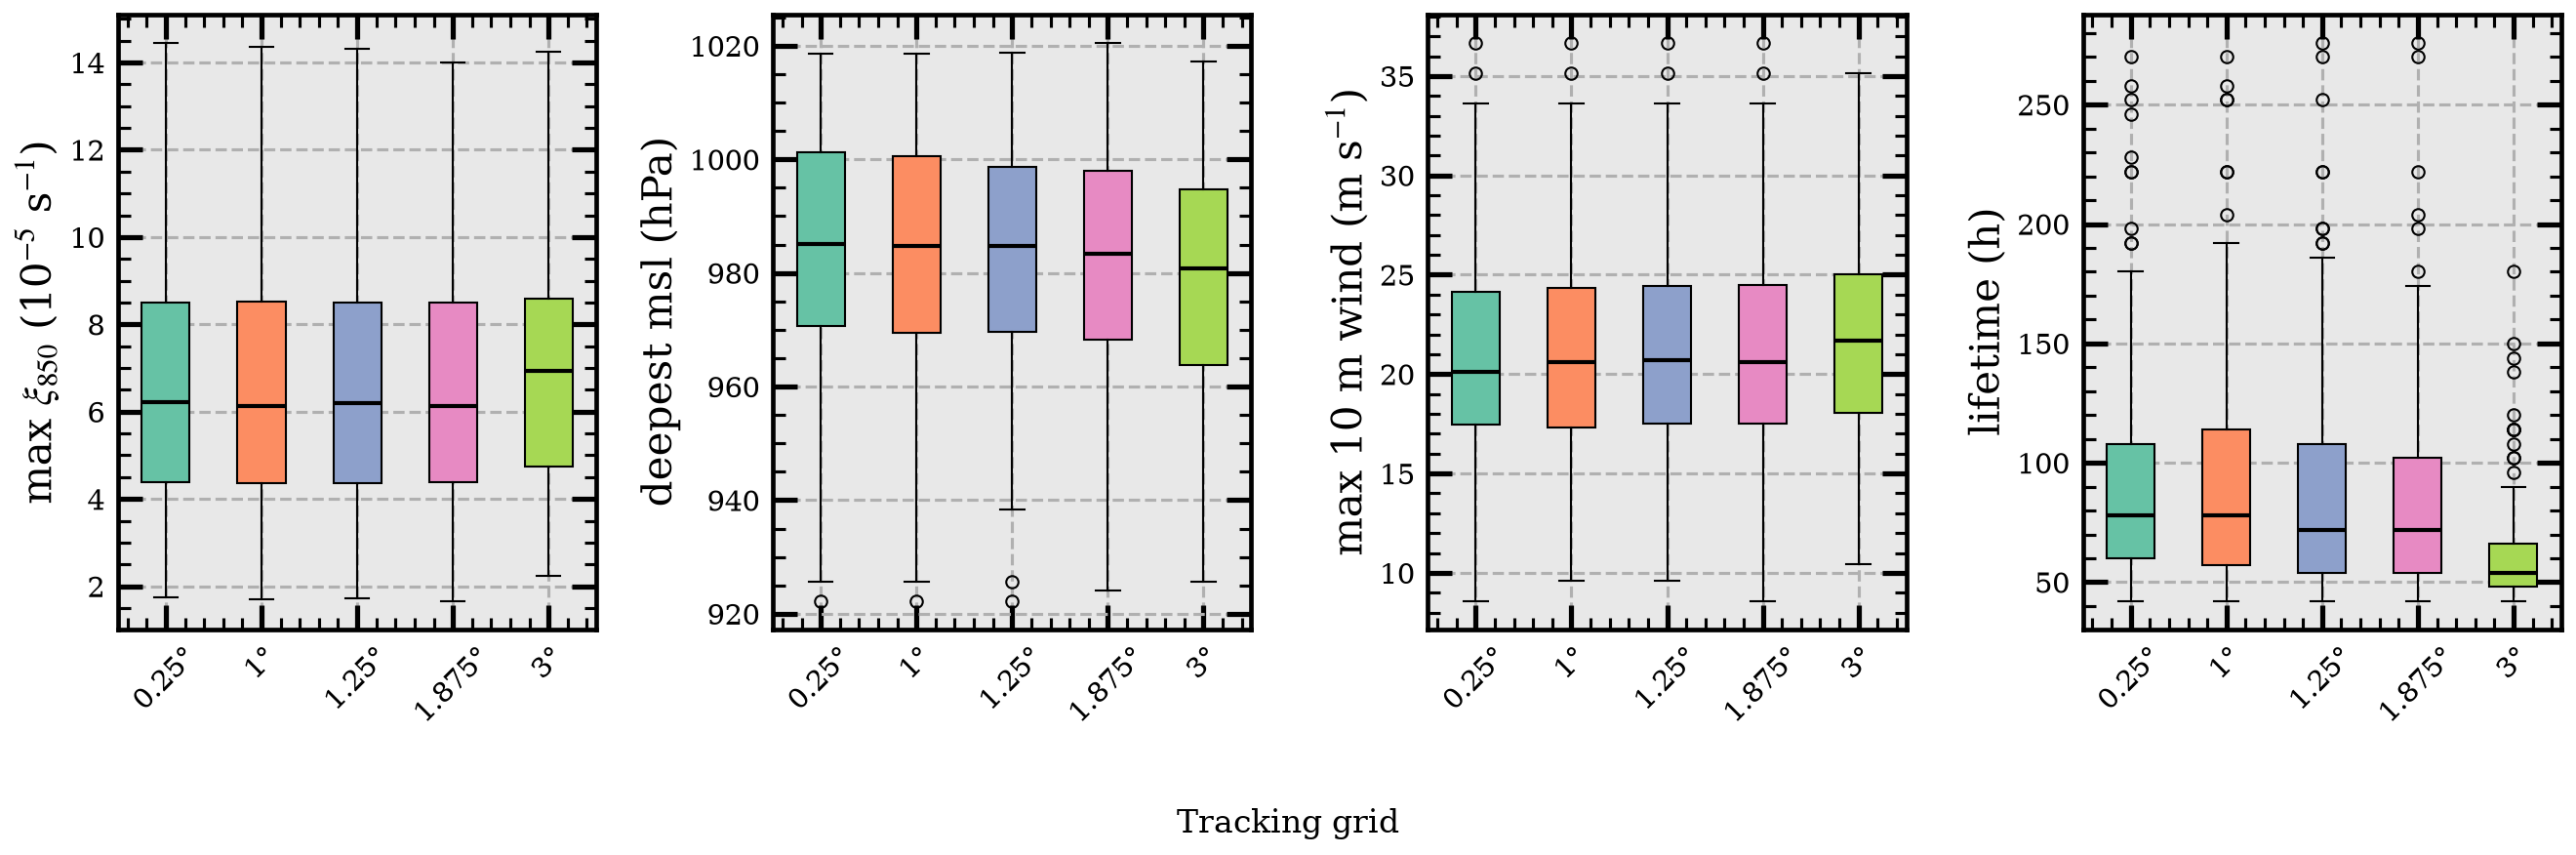

In [ ]:
variables = [("vo_max_1e5", r"max $\xi_{850}$ (10$^{-5}$ s$^{-1}$)"),
             ("msl_min_min", "deepest msl (hPa)"),
             ("ws10_max_max", "max 10 m wind (m s$^{-1}$)"),
             ("duration_h", "lifetime (h)")]
fig, axes = plt.subplots(1, len(variables), figsize=(18, 6))
for ax, (col, label) in zip(axes, variables):
    data = [summary.loc[summary.res == r, col].dropna() for r in RESOLUTIONS]
    bp = ax.boxplot(data, patch_artist=True, medianprops={"color": "k", "lw": 2})
    for patch, r in zip(bp["boxes"], RESOLUTIONS):
        patch.set_facecolor(RES_COLOR[r])
    ax.set_xticks(range(1, len(RESOLUTIONS) + 1), [res_label(r) for r in RESOLUTIONS], rotation=45)
    ax.set(ylabel=label)
fig.supxlabel("Tracking grid", fontsize=16)
fig.tight_layout()
plt.show()

A quantile–quantile plot compares the full distributions with the native grid. Each point is one percentile (1 … 99) of a coarse resolution against the same percentile at 0.25°. Points on the 1:1 line mean identical distributions; points below it mean the coarse grid finds weaker values at that percentile.

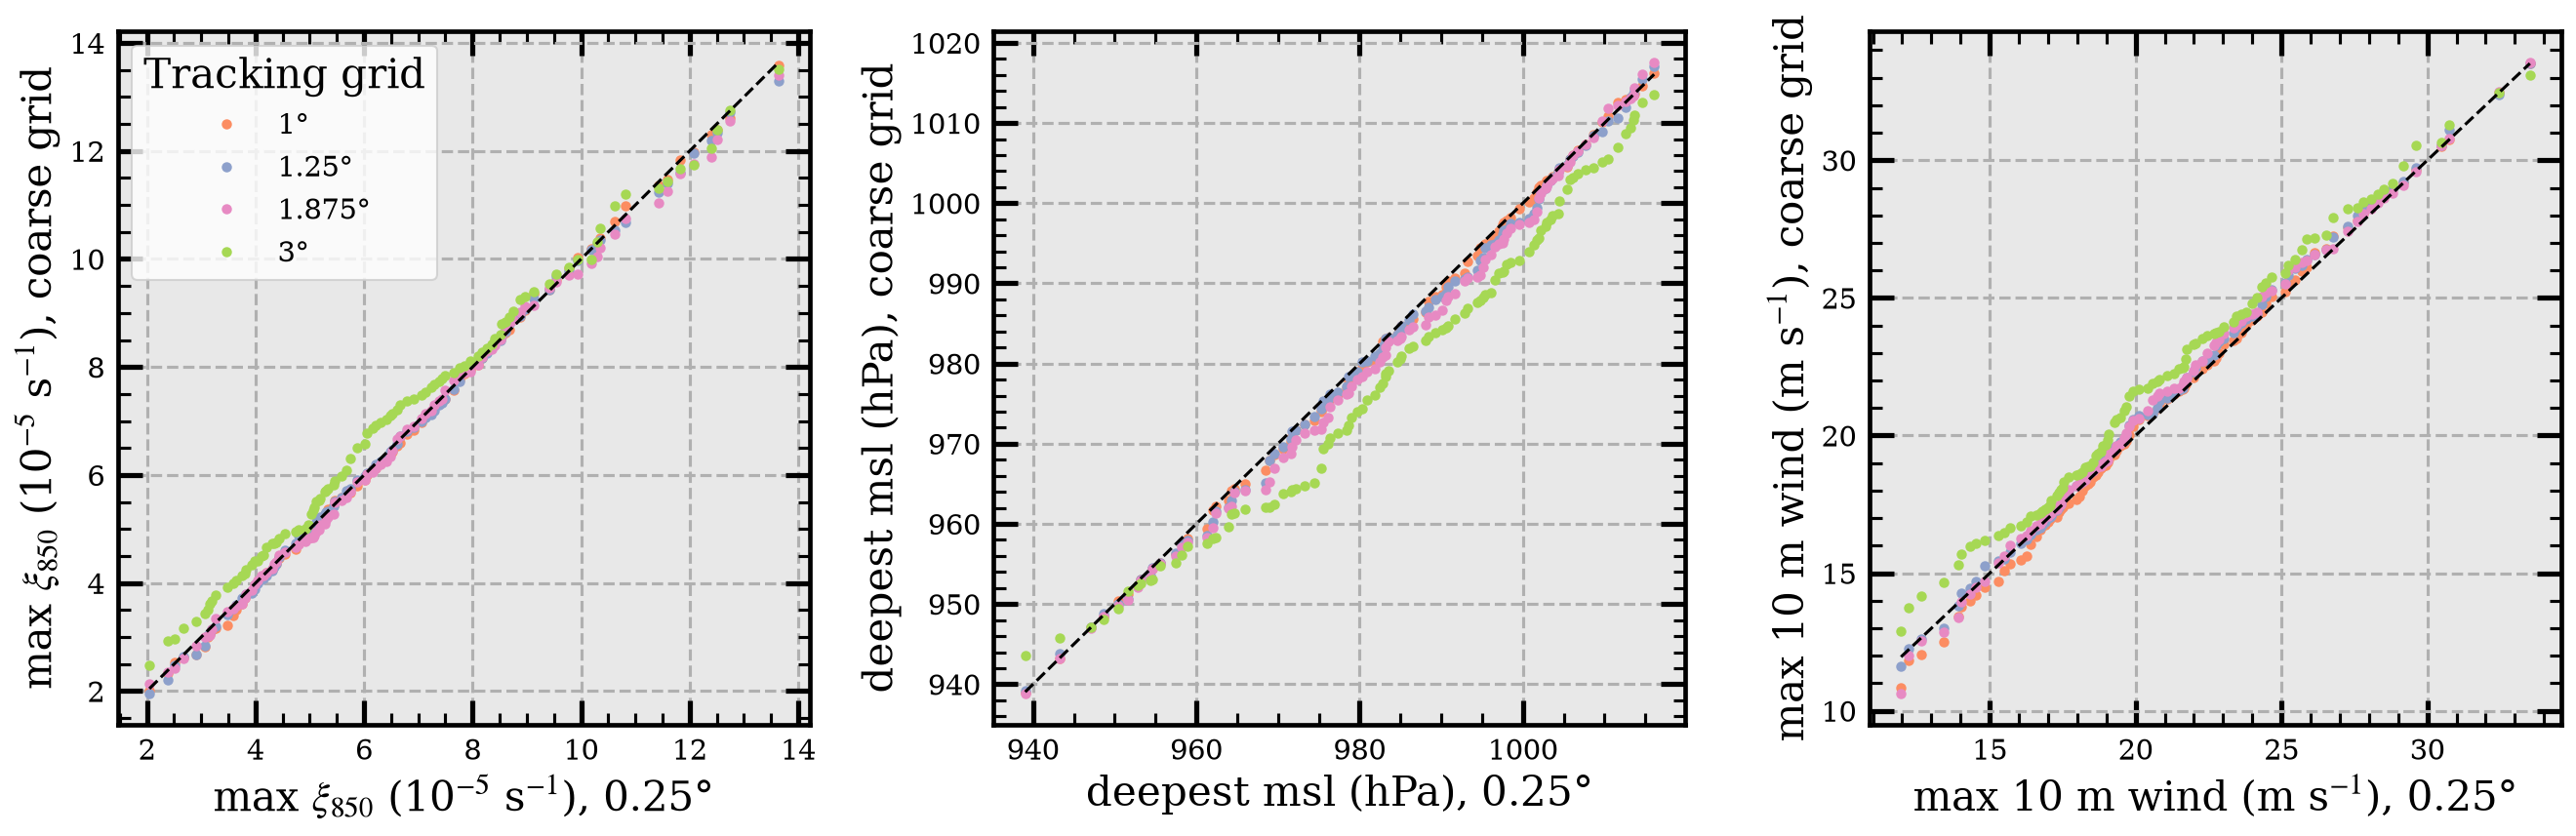

In [ ]:
q = np.arange(1, 100)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (col, label) in zip(axes, variables[:3]):
    ref = np.percentile(summary.loc[summary.res == fine, col].dropna(), q)
    for r in RESOLUTIONS[1:]:
        ax.plot(ref, np.percentile(summary.loc[summary.res == r, col].dropna(), q), "o", ms=4,
                color=RES_COLOR[r], label=res_label(r))
    lims = [ref.min(), ref.max()]
    ax.plot(lims, lims, "k--", lw=1.5)
    ax.set(xlabel=f"{label}, {res_label(fine)}", ylabel=f"{label}, coarse grid")
axes[0].legend(title="Tracking grid")
fig.tight_layout()
plt.show()

### 4.6 Effect of the sampling grid

The sampling script can also sample the same tracks from coarsened fields (`sample_on_seasons.py --sample-res 1.0`). This is the "model view": what a 1° model would report for the same storms. It is plotted here only if such files exist (currently for the 1° tracks of 1998/99).

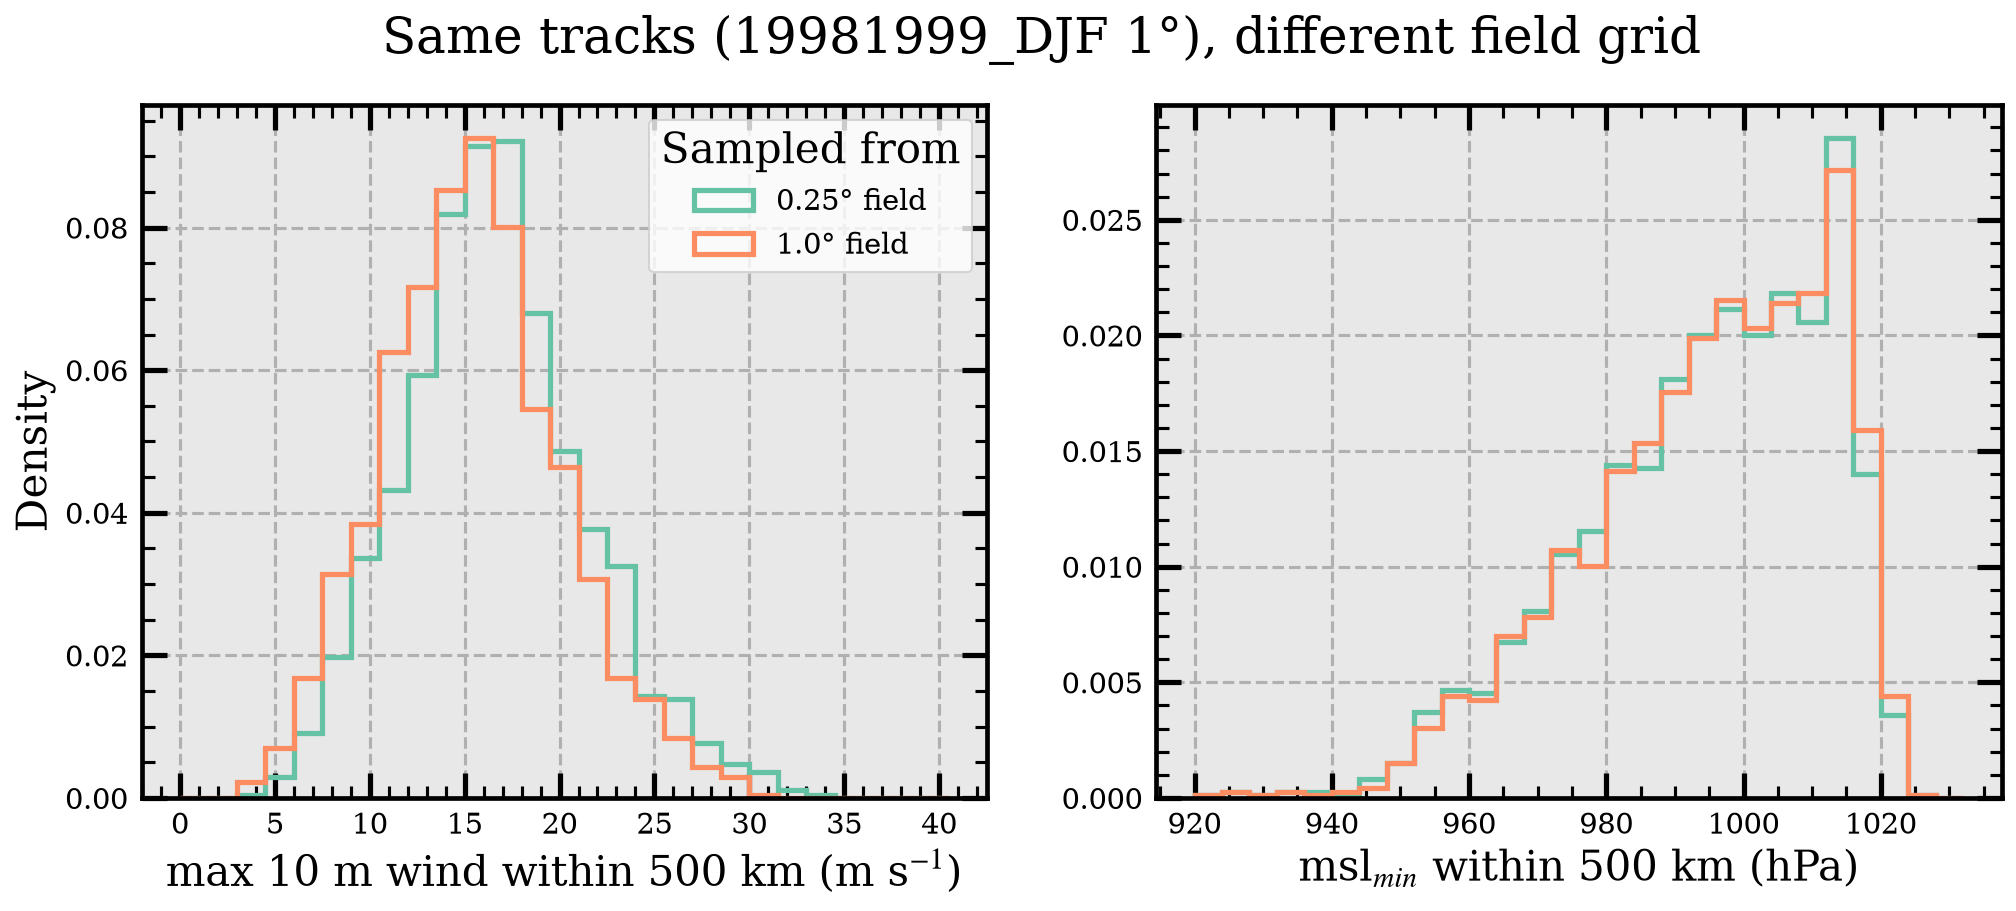

In [ ]:
coarse_grid = "sl1p0"
coarse_points = load_all("points", sample_grid=coarse_grid)
if coarse_points.empty:
    print(f"No {coarse_grid} files found")
else:
    keys = coarse_points[["season", "res"]].drop_duplicates()
    same = points.merge(keys, on=["season", "res"])
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
    for df, name in ((same, "0.25° field"), (coarse_points, "1.0° field")):
        ax1.hist(df["ws10_max"].dropna(), bins=np.arange(0, 41, 1.5), density=True, histtype="step", lw=2.5, label=name)
        ax2.hist(df["msl_min"].dropna(), bins=np.arange(920, 1036, 4), density=True, histtype="step", lw=2.5, label=name)
    ax1.set(xlabel="max 10 m wind within 500 km (m s$^{-1}$)", ylabel="Density")
    ax2.set(xlabel="msl$_{min}$ within 500 km (hPa)")
    ax1.legend(title="Sampled from")
    fig.suptitle(f"Same tracks ({', '.join(f'{s} {res_label(r)}' for s, r in keys.itertuples(index=False))}), different field grid")
    plt.show()

## 5. Further suggestions

* **More seasons:** with all 86 seasons, normalise counts per season, and split the distributions by decade or by NAO phase to look for trends and variability.
* **Regional statistics:** restrict to points inside `REGION` (`helpers._in_box`), or to tracks that pass over a target area (e.g. Scandinavia), before making distributions.
* **Uncertainty:** bootstrap over seasons (resample whole seasons with replacement) to put confidence bands on the histograms and on the fractions of gale or explosive storms.
* **Percentile thresholds:** compare against local climatological percentiles (e.g. the 98th percentile of 10 m wind, as in a storm severity index) instead of fixed thresholds.
* **Precipitation:** needs hourly `total_precipitation` summed to 6 h totals (see `experiments/download_all/README.md`).